In [53]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import os #used to work with folders and file paths
from PIL import Image # PIL is Pillow module, Image is a module for working with Images
import random
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,MaxPool2D,GlobalAveragePooling2D,Flatten,Dense,Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator #used for image preprocessing and data augmentation
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau,ModelCheckpoint
#Early Stopping prevents overfitting
#ReduceLROnPlateau reduces the learnign rate when the validation performance stops improving

#### Set Random Seed

This makes the results more reproducibile instead of randomness

In [54]:
SEED=42
#use the same number whenever you want to reproduce the same results
#If you run the code again with the same seed, you'll get the same random numbers.
random.seed(SEED) #This controls Python's built-in random module.
np.random.seed(SEED) #This controls NumPy's random operations.
tf.random.set_seed(SEED) #This controls randomness generated by TensorFlow.

In [55]:
DATASET_DIR=r"/kaggle/input/datasets/bhavikjikadara/dog-and-cat-classification-dataset/PetImages"
#we decide the label maps, we can make anything we want, here we made cat 0, dog 1
LABEL_MAP={
    "Cat":0,
    "Dog":1
}
#its a dictionary to map the labels to corresponding values

#### Collect image paths

In [56]:
#create 2 empty lists, one to store the image paths, and one for the corresponding label
image_paths=[]
labels=[]
#image_paths → where the image is located
#labels      → what class the image belongs to
for class_name,class_label in LABEL_MAP.items():
    #we loop through the items ie through cat class and dog class
    #ie we get 2 pairs ("cat", 0), ("dog", 1) and we loop on each
    #so in first iteration: class_name="cat", class_label=0
    #and in second iteration: class_name="dog", class_label=1
    class_dir=os.path.join(DATASET_DIR,class_name) #PetImages/Cat and PetImages/Dog
    for filename in os.listdir(class_dir):#listdir gets all files inside that folder
        image_path=os.path.join(class_dir,filename)#PetImages/Cat/1.jpg for example
        image_paths.append(image_path)
        labels.append(class_label)
print(f"Image Path: {image_paths[5]} and label: {labels[5]}")

Image Path: /kaggle/input/datasets/bhavikjikadara/dog-and-cat-classification-dataset/PetImages/Cat/10304.jpg and label: 0


#### Creating DataFrame

In [57]:
df=pd.DataFrame({
    "image":image_paths,
    "label":labels
})
df.head()

,image,label
0,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
1,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
2,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
3,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
4,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0


In [58]:
print("Total Number of Images: ", len(df))
print(df['label'].value_counts())

Total Number of Images:  24998
label
0    12499
1    12499
Name: count, dtype: int64


#### Check Class Balance

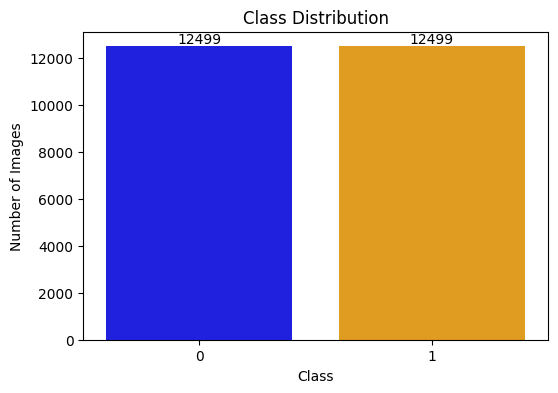

In [59]:
plt.figure(figsize=(6,4))#6 width and 4 height
ax=sns.countplot(x=df['label'],hue=df['label'],palette=['blue','orange'],legend=False)
#hue tells Seaborn to separate the data by category, which allows the palette to assign different colors
#ax is the Axes object, which lets you modify the chart afterward
for container in ax.containers:
    ax.bar_label(container) #This puts the exact count on top of the bars
#ax.containers refers to the bars created by the countplot
#bar_label() then writes their values above them
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

#### Find corrupted images automatically

In [60]:
valid_images=[]
#empty list to place the valid images in it
for image_path in df['image']:
    try:
        with Image.open(image_path) as img: # Attempts to open the image
            img.verify() # Checks whether the image file is valid/corrupted
        valid_images.append(image_path)
    except Exception: #If the image can't be opened, we don't keep it.
        print("Invalid image: ", image_path)

In [61]:
print(f"Valid Images Count: {len(valid_images)} out of {len(df)} images.")

Valid Images Count: 24998 out of 24998 images.


Remove invalid images from df

In [62]:
df = df[df["image"].isin(valid_images)].reset_index(drop=True)

#### Shuffle the dataset

We need to shuffle the dataset so the cat and dog images are mixed instead of having all the cat images first followed by all the dog images

In [63]:
df=df.sample(frac=1,random_state=SEED).reset_index(drop=True)
#frac=1 means shuffle 100% of the DataFrame
#random_state=SEED makes the shuffle reproducible by the same seed we decided at the begining
df.head()

,image,label
0,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
1,/kaggle/input/datasets/bhavikjikadara/dog-and-...,1
2,/kaggle/input/datasets/bhavikjikadara/dog-and-...,0
3,/kaggle/input/datasets/bhavikjikadara/dog-and-...,1
4,/kaggle/input/datasets/bhavikjikadara/dog-and-...,1


#### Display random images

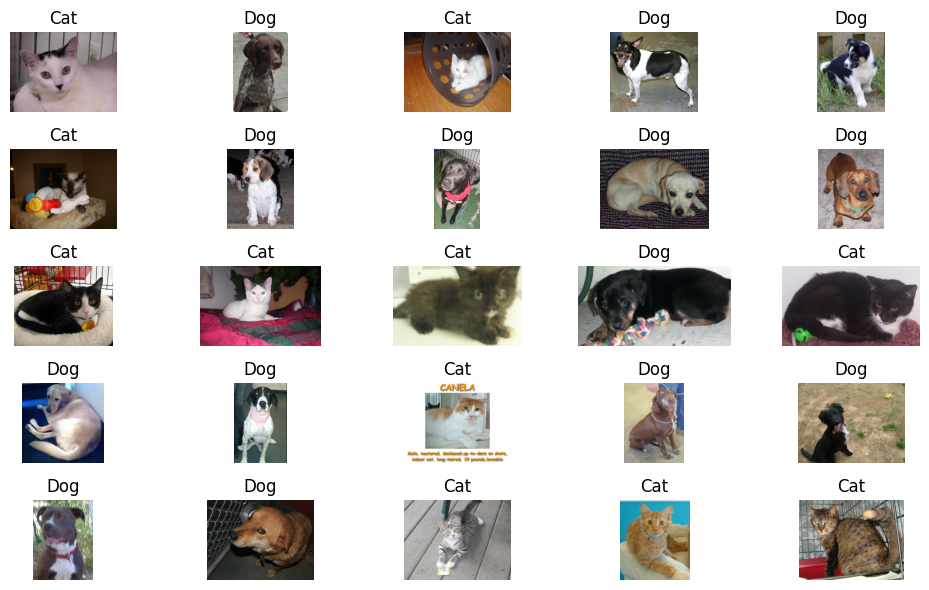

In [64]:
plt.figure(figsize=(10,6))
#sample 25 random images
sample_df=df.sample(25,random_state=SEED)
#25 means randomly choose 25 rows from the df
for i,(_,row) in enumerate(sample_df.iterrows()):
    #iterrows() goes through the DataFrame one row at a time, each iteration gives you (index,row)
    #here we dont care about index, so use _ to ignore it bec _ means I dont need it
    #row will contain 2 cols image,label
    #we dont care about
    #enumerate() gives you a counter i along with each row.
    #so now i will have image number, row will have image,label
    image=Image.open(row['image'])
    plt.subplot(5,5,i+1)
    plt.imshow(image)
    label_name = "Dog" if row["label"] == 1 else "Cat"
    plt.title(label_name)
    plt.axis("off") #means hide the axes around the image so you can only see the image
plt.tight_layout()
plt.show()

#### Split into train, validation and test

We'll use:\
70% train\
15% validation\
15% test

In [65]:
train_df,temp_df=train_test_split(df,test_size=0.3,random_state=SEED,stratify=df['label'])
#stratify keeps the Cat/Dog distribution similar
#Without stratification, random splitting could produce slightly different distributions
val_df,test_df=train_test_split(temp_df,test_size=0.5,random_state=SEED,stratify=temp_df['label'])
print("Train Split: ",len(train_df))
print("Validation Split: ",len(val_df))
print("Test Split: ",len(test_df))

Train Split:  17498
Validation Split:  3750
Test Split:  3750


#### Convert Labels to Strings:

In [66]:
train_df['label']=train_df['label'].astype('str')
val_df['label']=val_df['label'].astype('str')
test_df['label']=test_df['label'].astype('str')
#we need them as strings for later, not numbers

#### Define image size and batch size

In [67]:
IMG_SIZE=(128,128)
BATCH_SIZE=64

#### Training Image Generator

train_generator defines how the images should be processed/augmented before being given to the CNN

In [68]:
train_data_gen=ImageDataGenerator(
    rescale=1.0/255, #converts pixel values from 0-255 into 0-1
    rotation_range=20, #randomly rotates images by up to 20°
    width_shift_range=0.1, #moves the image horizontally by up to 10%
    height_shift_range=0.1, #moves the image vertically by up to 10%
    zoom_range=0.2, #random zooming
    shear_range=0.1, #small shear transformation
    horizontal_flip=True, #flips some images horizontally, this is very useful for animals
    fill_mode="nearest" #fills newly created pixels using nearby pixels
    #When we rotate, shift, or shear an image, some new areas may appear where there were previously no pixels
    #there may be empty corners
    #"nearest" fills those new pixels using the nearest existing pixel values
    #So instead of leaving empty areas, Keras fills them based on nearby pixels
)

In [69]:
#for validation and test, we don't need two separate generators for validation and test
#they are identical so we can just use one generator for both
val_test_data_gen=ImageDataGenerator(
    rescale=1.0/255
)
#only rescale, no augmentation because augmentation is for train only

#### Create training, validation and test iterators

Training Iterator is actually applying the train data gen to my train df\
It takes the train_df and applies the train_data_gen preprocessing and augmentation to the images

In [70]:
train_iterator=train_data_gen.flow_from_dataframe( 
    # .flow_from_dataframe() is the function that connects your DataFrame to the ImageDataGenerator
    train_df,
    x_col='image', # x is the input to model
    y_col='label', # y is the target of model
    target_size=IMG_SIZE, # This tells Keras to resize every image to IMG_SIZE
    batch_size=BATCH_SIZE, #dont give the CNN the entire dataset at once, give it BATCH_SIZE each time
    class_mode='binary', #binary classification
    #if multiclass classification so class_model='categorical'
    shuffle=True, #it means that in the iterator means the training batches can be shuffled during training, including between epochs
    #so batch images are shuffled in each epoch
    seed=SEED
)

Found 17498 validated image filenames belonging to 2 classes.


In [71]:
val_iterator=val_test_data_gen.flow_from_dataframe(
    val_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False # because for validation and test, we don't need to randomize the order, we mainly want to evaluate with them
)

Found 3750 validated image filenames belonging to 2 classes.


In [72]:
test_iterator=val_test_data_gen.flow_from_dataframe(
    test_df,
    x_col='image',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

Found 3750 validated image filenames belonging to 2 classes.


#### Creating the CNN

Both Flatten() and GlobalAveragePooling2D() convert the 3D feature maps coming from convolution layers into something that can go into a Dense layer. But they do it very differently.

In [73]:
model=Sequential([
    #Layer 1
    Conv2D(32,(3,3),activation='relu',input_shape=((*IMG_SIZE,3))),
    # The * here means unpack.
    # IMG_SIZE=(128,128)
    # so (*IMG_SIZE,3) means Python expands (*IMG_SIZE, 3) into (128,128,3)
    BatchNormalization(),
    #Batch normalization helps keep activations in a more stable range during training
    #It's not mandatory, but it's a useful improvement to this CNN
    MaxPool2D((2,2)),
    #Layer 2
    Conv2D(64,(3,3),activation='relu'),
    BatchNormalization(),
    MaxPool2D((2,2)),
    #Layer 3
    Conv2D(128,(3,3),activation='relu'),
    BatchNormalization(),
    MaxPool2D((2,2)),
    #Layer 4
    #Classifier
    GlobalAveragePooling2D(),
    Dense(128,activation='relu'),
    Dropout(0.4),
    #Output
    Dense(1,activation='sigmoid')
])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [74]:
opt=keras.optimizers.Adam(learning_rate=1e-3)
precision=keras.metrics.Precision()
recall=keras.metrics.Recall()
model.compile(loss='binary_crossentropy',optimizer=opt,metrics=['accuracy',precision,recall])

In [75]:
early_stop=EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

In [76]:
lr_scheduler=ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-6
)

In [77]:
checkpoint=ModelCheckpoint(
    "best_cnn_model.keras",
    monitor='val_loss',
    save_best_only=True
)

In [78]:
history=model.fit(train_iterator,epochs=30,validation_data=val_iterator,callbacks=[lr_scheduler, early_stop, checkpoint])
#no need for batch_size because we alreayd specified that in train_iterator

Epoch 1/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 118s 411ms/step - accuracy: 0.6294 - loss: 0.6456 - precision_2: 0.6325 - recall_2: 0.6180 - val_accuracy: 0.5003 - val_loss: 0.7570 - val_precision_2: 0.5714 - val_recall_2: 0.0021 - learning_rate: 0.0010
Epoch 2/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 104s 381ms/step - accuracy: 0.6842 - loss: 0.5913 - precision_2: 0.6920 - recall_2: 0.6640 - val_accuracy: 0.5205 - val_loss: 0.8375 - val_precision_2: 0.9873 - val_recall_2: 0.0416 - learning_rate: 0.0010
Epoch 3/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 104s 379ms/step - accuracy: 0.7191 - loss: 0.5544 - precision_2: 0.7282 - recall_2: 0.6993 - val_accuracy: 0.7072 - val_loss: 0.5609 - val_precision_2: 0.6756 - val_recall_2: 0.7973 - learning_rate: 0.0010
Epoch 4/30
274/274 ━━━━━━━━━━━━━━━━━━━━ 103s 375ms/step - accuracy: 0.7361 - loss: 0.5295 - precision_2: 0.7460 - recall_2: 0.7161 - val_accuracy: 0.7381 - val_loss: 0.5321 - val_precision_2: 0.7099 - val_recall_2: 0.8053 - learning_rate: 0.0010
Epoch 5/30
274/2

In [79]:
test_results=model.evaluate(test_iterator,return_dict=True)
#you will get results in a dictionary with name and value
print(test_results)

59/59 ━━━━━━━━━━━━━━━━━━━━ 12s 203ms/step - accuracy: 0.9003 - loss: 0.2395 - precision_2: 0.8956 - recall_2: 0.9061
{'accuracy': 0.9002666473388672, 'loss': 0.23948433995246887, 'precision_2': 0.8956246972084045, 'recall_2': 0.9061333537101746}


#### Accuracy and Loss Graphs

Accuracy Graph

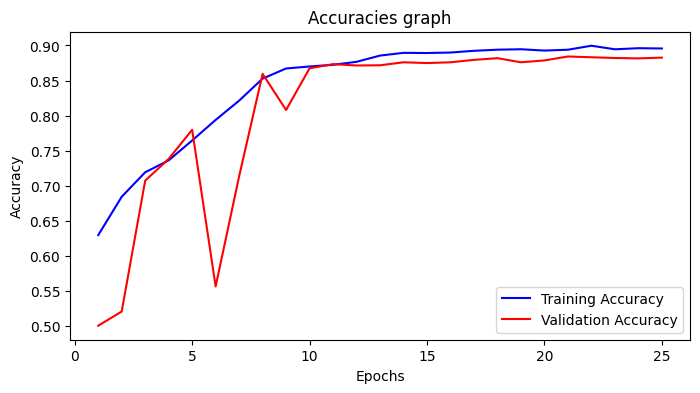

In [80]:
plt.figure(figsize=(8,4))
train_acc=history.history['accuracy']
val_acc=history.history['val_accuracy']
epochs = range(1, len(train_acc) + 1)
plt.plot(epochs,train_acc,'b',label="Training Accuracy")
plt.plot(epochs,val_acc,'r',label="Validation Accuracy")
plt.title("Accuracies graph")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Loss Graph

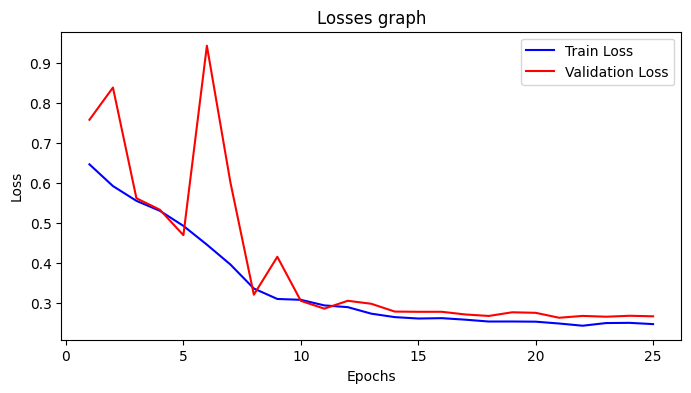

In [81]:
plt.figure(figsize=(8,4))
train_loss=history.history['loss']
val_loss=history.history['val_loss']
epochs=range(1,len(train_loss)+1)
plt.plot(epochs,train_loss,'b',label="Train Loss")
plt.plot(epochs,val_loss,'r',label="Validation Loss")
plt.title("Losses graph")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

#### Test with Real Images

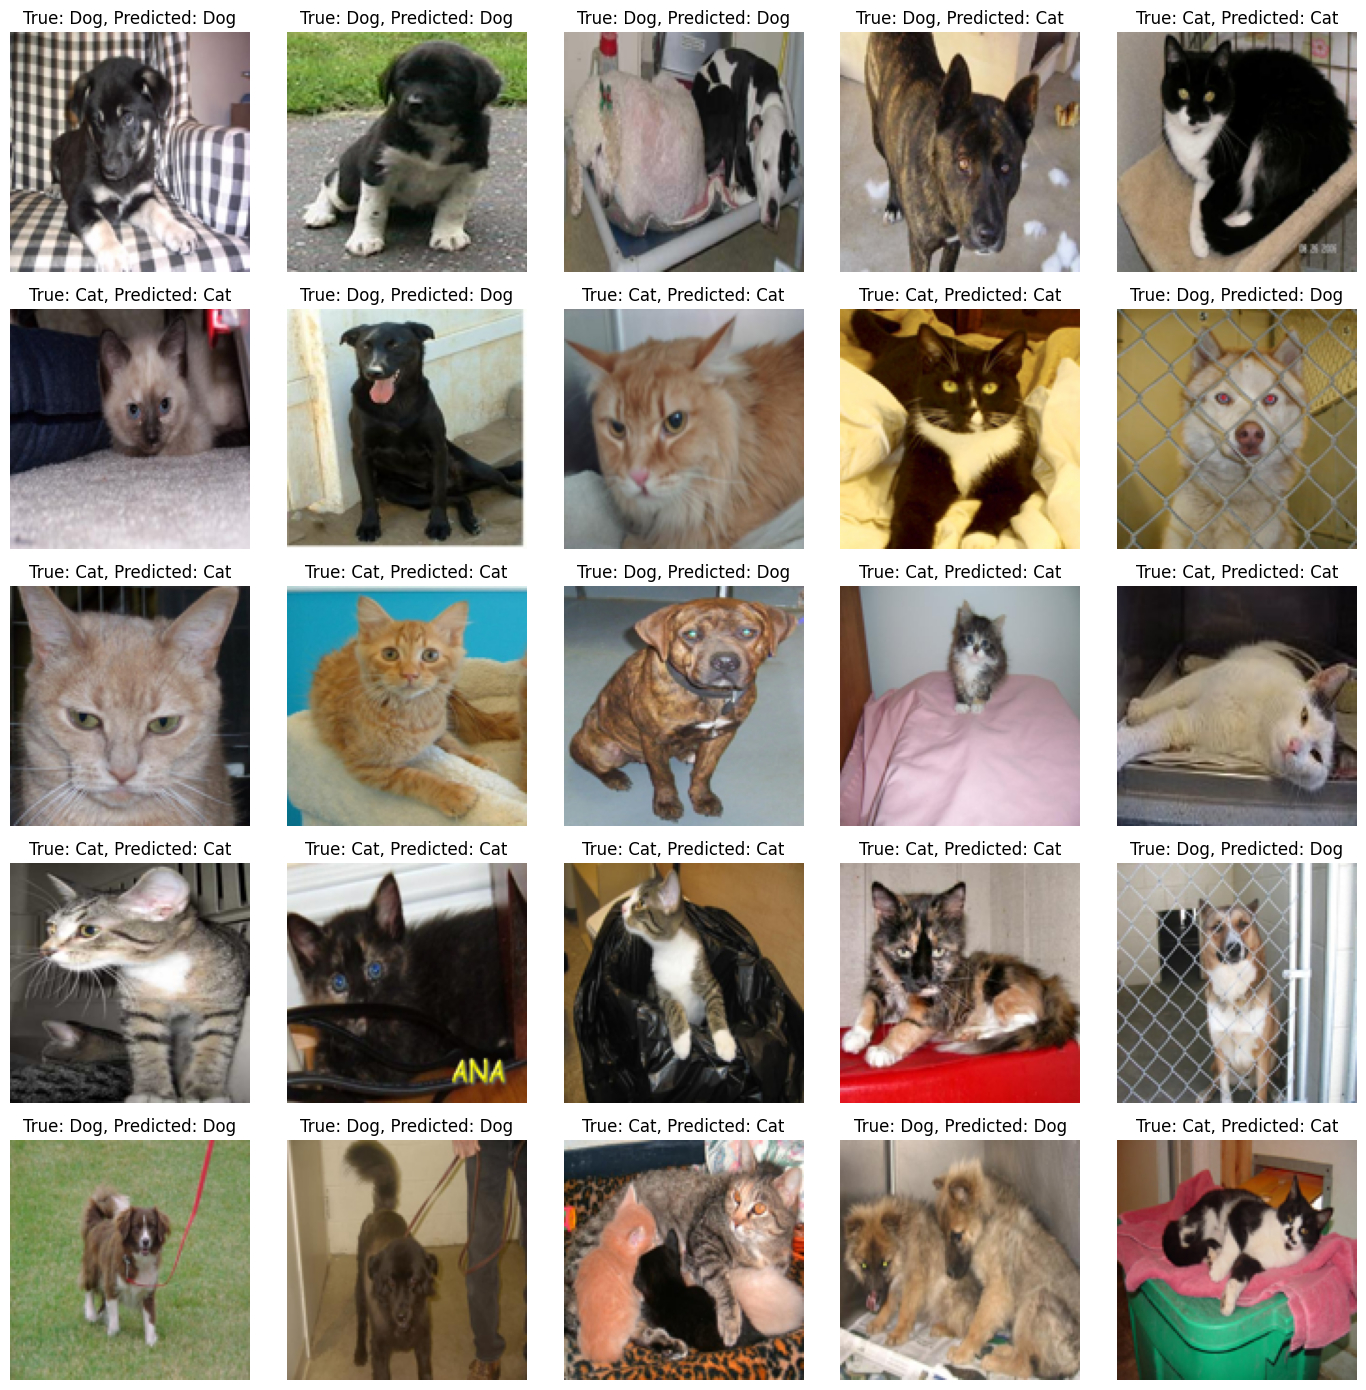

In [82]:
plt.figure(figsize=(14,14))
test_sample=test_df.sample(25,random_state=SEED)
for i,(_,row) in enumerate(test_sample.iterrows()):
    plt.subplot(5,5,i+1)
    img_path=row['image']
    true_label="Cat" if row['label']=='0' else "Dog"
    img=Image.open(img_path).convert('RGB').resize(IMG_SIZE) #convert to RGB and resize
    plt.imshow(img)
    img=np.array(img,dtype=np.float32) #convert image to np array
    img=img/255.0 #rescale to range 0-1
    img=np.expand_dims(img,axis=0)
    #image shape is (128,128,3) but CNN expects (no_of_images_in_batch,128,128,3)
    #so we use expand_dims with axis=0 which means add new dimension at position 0 with size 1
    #so now instead of (128,128,3) it becomes (1,128,128,3) which is:
    # 1 image
    # 128 height
    # 128 width
    # 3 channels
    prediction_prob=model.predict(img,verbose=0)[0][0]
    # verbose=0 means don't display a progress bar while making predictions
    # model.predict(img) returns an array containing the prediction for each image
    # [0] selects the prediction for the first image in the batch
    # [0] selects the first (and only) output value: the probability of Dog (class 1)
    predicted_label="Dog" if prediction_prob>=0.5 else "Cat"
    plt.title(f"True: {true_label}, Predicted: {predicted_label}")
    plt.axis('off')
plt.tight_layout()
plt.show()

#### Confusion Matrix

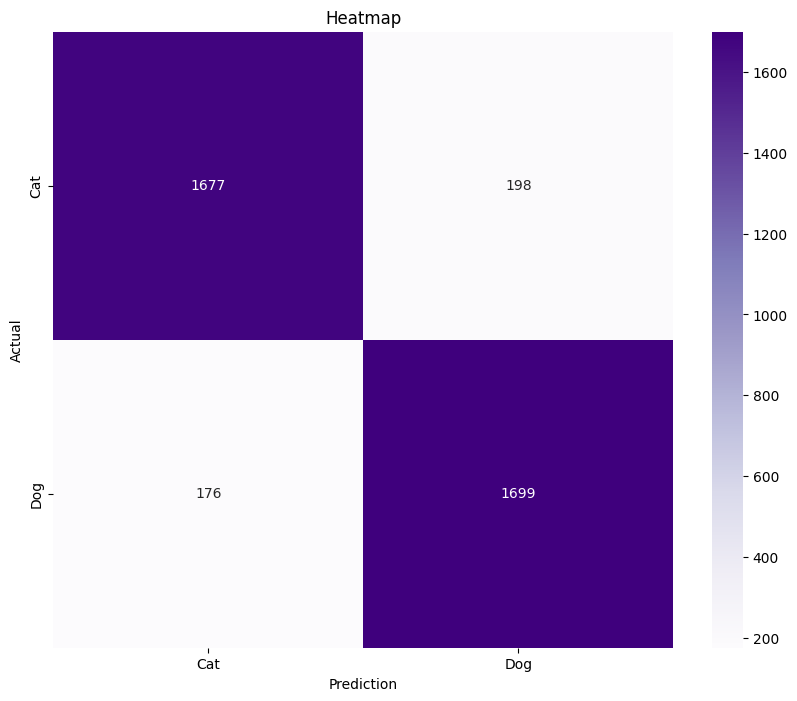

In [83]:
plt.figure(figsize=(10,8))
y_true=test_iterator.classes #to get the classes
y_pred_prob=model.predict(test_iterator,verbose=0)
# verbose=0 means don't display a progress bar while making predictions
y_pred=y_pred_prob.ravel()>=0.5
# model uses a sigmoid output, so it predicts a probability between 0 and 1 for each image
# so we need .ravel()
''' ex:
y_pred_prob = [[0.12],
               [0.85],
               [0.43],
               [0.91]]
so if we use .ravel(): it will convert the 2D array into a 1D array so we get:
[0.12, 0.85, 0.43, 0.91]
now for >= 0.5:
y_pred_prob.ravel() >= 0.5
This compares each probability with the threshold 0.5 (50%)
if >=0.5 returns True else False
so the final result is: [False, True, False, True]
'''
y_pred=y_pred.astype(int)
cm=confusion_matrix(y_true,y_pred,labels=[0,1])
sns.heatmap(cm,annot=True,fmt='d',cmap="Purples",xticklabels=['Cat','Dog'],yticklabels=['Cat','Dog'])
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.title("Heatmap")
plt.show()

#### Classification Report

In [84]:
print(classification_report(y_true,y_pred,labels=[0,1],target_names=["Cat","Dog"]))

              precision    recall  f1-score   support

         Cat       0.91      0.89      0.90      1875
         Dog       0.90      0.91      0.90      1875

    accuracy                           0.90      3750
   macro avg       0.90      0.90      0.90      3750
weighted avg       0.90      0.90      0.90      3750



#### Visualizing Wrong Predictions

creating dataframe for wrong predictions

In [86]:
wrong_df=pd.DataFrame(columns=['image','label','prediction'])
for _,row in test_df.iterrows():
    image_path=row['image']
    image_true_label=row['label']
    image_true_label = {str(v): k for k, v in LABEL_MAP.items()}[image_true_label]
    image=Image.open(image_path).convert('RGB').resize(IMG_SIZE)
    image=np.array(image,dtype=np.float32)
    image = np.expand_dims(image, axis=0)
    image_pred_prob=model.predict(image,verbose=0)[0][0]
    image_pred_label="Dog" if image_pred_prob>=0.5 else "Cat"
    if(image_true_label!=image_pred_label):
        wrong_df.loc[len(wrong_df)]=[image_path,image_true_label,image_pred_label]
print(f"Number of wrong predictions: {len(wrong_df)} out of {len(test_df)} predictions.")

Number of wrong predictions: 914 out of 3750 predictions.


In [87]:
wrong_df.head()

,image,label,prediction
0,/kaggle/input/datasets/bhavikjikadara/dog-and-...,Cat,Dog
1,/kaggle/input/datasets/bhavikjikadara/dog-and-...,Cat,Dog
2,/kaggle/input/datasets/bhavikjikadara/dog-and-...,Dog,Cat
3,/kaggle/input/datasets/bhavikjikadara/dog-and-...,Cat,Dog
4,/kaggle/input/datasets/bhavikjikadara/dog-and-...,Cat,Dog


displaying wrong predictions

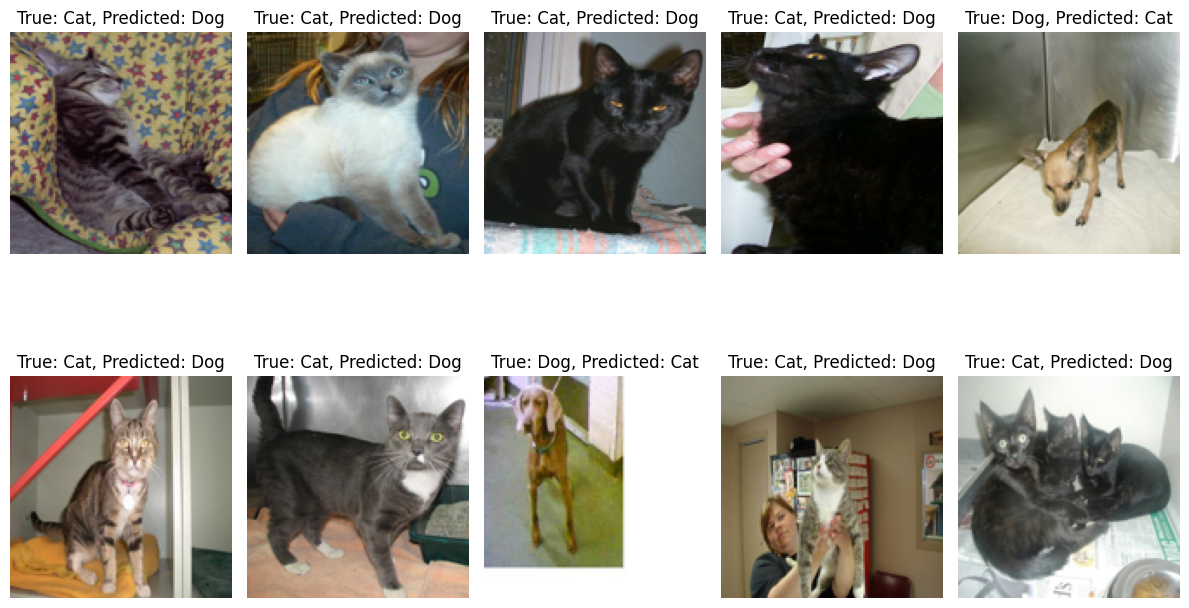

In [92]:
plt.figure(figsize=(12,8))
sample_df2=wrong_df.sample(10,random_state=SEED)
for i,(_,row) in enumerate(sample_df2.iterrows()):
    image_path=row['image']
    true_label=row['label']
    pred_label=row['prediction']
    image=Image.open(image_path).convert('RGB').resize(IMG_SIZE)
    plt.subplot(2,5,i+1)
    plt.imshow(image)
    plt.title(f"True: {true_label}, Predicted: {pred_label}")
    plt.axis('off')
plt.tight_layout()
plt.show()